# Chapter 14: Who Benefits? Uplift Models and Targeting Policies

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Who Benefits? Uplift Models and Targeting Policies](https://books.sugiv.fyi/lift/who-benefits.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, export_text
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import uplift as U, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


R = U.review_test()
glue_num("rv_ate", 100 * (R.retained[R.offered == 1].mean() - R.retained[R.offered == 0].mean()))
glue_num("rv_true_ate", 100 * R.true_effect.mean())
glue_num("rv_helped", 100 * (R.true_effect > 0).mean())

Here's the finding first. Juno's team tested a **proactive review offer**: when a learner opens the app, Juno suggests a five-minute review of recent mistakes. The A/B test came back flat: **+0.8 points of day-30 retention**, not significant, not worth the tokens. The team almost deleted the feature.

Underneath that flat average, the offer helps 54% of learners, the ones who are struggling or drifting away, and mildly annoys most of the rest, confident regulars who didn't want a lesson about lessons. A targeting rule learned from the same A/B test, offered only where it helps, is worth many times as much as offering it to everyone.

An average treatment effect answers "should everyone get this?". This chapter answers "**who** should get this?". That's how you get from Part I's careful averages to a product that treats each learner as an individual, without giving up the rigour:

1. Estimate how the effect varies across learners (uplift models).
2. Check those estimates honestly on held-out data (uplift curves).
3. Turn them into a rule, and estimate what the rule is worth before shipping it (policy learning).

> **Note**
>
> The numbers come from `lift/sim/uplift.py`: a randomised test of a Premium discount (revenue) and a randomised test of Juno's review offer (retention). Both are 50/50 experiments, so every method here rests on randomisation, not on the assumptions of Part III.

## Four kinds of learner

The classic way to think about targeting comes from marketing, and the Premium discount shows it best. Parlo randomly offered 30% off Premium to half of a group of learners. Every learner falls into one of four types, depending on what they'd do with and without the offer. The god view knows which:

In [3]:
Dd = U.discount_test()
types = Dd.groupby("segment").agg(share=("realised_uplift", "size"), revenue_effect=("realised_uplift", "mean"))
types["share"] /= len(Dd)
types.loc[["persuadable", "buys anyway", "never buys", "put off"]].style.format(
    {"share": "{:.1%}", "revenue_effect": "${:+.2f}"})

,share,revenue_effect
segment,,
persuadable,4.7%,$+42.00
buys anyway,9.2%,$-18.00
never buys,85.9%,$+0.00
put off,0.2%,$-60.00


In [4]:
glue_num("disc_ate", Dd.true_uplift.mean())

- **Persuadables** buy only with the discount. This is the whole point of the offer.
- **Buys anyway**: they'd pay full price, so the discount just gives away \$18.
- **Never buys**: the offer is wasted on them, but costs nothing.
- **Put off**: a discount makes the product look cheap. Rare, but real.

On average the offer adds just \$0.19 per learner: the persuadables' \$42 is mostly cancelled by the \$18 handed to each of the more numerous learners who'd have paid anyway. In real data you never see these types, because each learner is in only one arm. What you *can* estimate is the **conditional average treatment effect** (CATE): the expected effect for learners who look like this one.

## Uplift models: estimating the effect for each learner

Two simple, strong approaches, both built from ordinary machine-learning models:

- **T-learner.** Fit one model predicting revenue for offered learners, another for non-offered learners. The predicted uplift is the difference (K\"unzel et al., 2019).
- **DR-learner.** For each learner, build Chapter 11's doubly robust score (an unbiased but noisy estimate of *their* effect, using the known 50% propensity), then fit one model predicting that score from the features. It targets the uplift directly instead of hoping two separate models subtract cleanly (Kennedy, 2023).

Fit on one half of the data; evaluate on the other:

In [5]:
features = ["lessons_wk1", "active_days_wk1", "tier", "trial_over"]
train = np.arange(len(Dd)) < len(Dd) // 2
test = ~train
X, t, y = Dd[features].values, Dd.offer.values, Dd.revenue.values

uplift_t = U.t_learner(X[train], t[train], y[train], X[test])
uplift_dr, _ = U.dr_learner(X[train], t[train], y[train], X[test])
true_test = Dd.true_uplift.values[test]
pd.Series({"T-learner": np.corrcoef(uplift_t, true_test)[0, 1],
           "DR-learner": np.corrcoef(uplift_dr, true_test)[0, 1]}).round(2).to_frame("correlation with true uplift")

,correlation with true uplift
T-learner,0.87
DR-learner,0.87


Both track the true uplift well. In real life you can't compute that correlation, because you never see the true uplift. So you need a check that uses only the data.

## Checking an uplift model honestly

The **uplift curve** (a close cousin of the Qini curve) answers a practical question: *if we offered the discount only to the top X% of learners by predicted uplift, how much extra revenue would we make?* On the held-out half, which was randomised, you can estimate that for any X with the same inverse propensity weighting as Chapter 10: within the top X%, compare offered and non-offered learners.

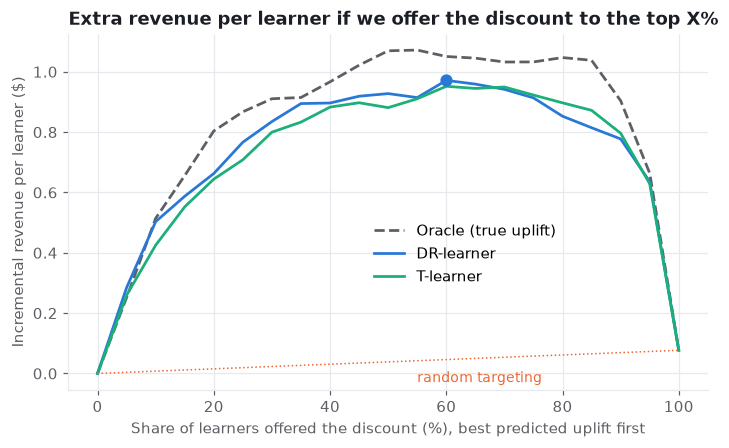

In [6]:
fig, ax = plt.subplots()
curves = {}
for name, score, colour in [("Oracle (true uplift)", true_test, style.MUTED),
                            ("DR-learner", uplift_dr, style.SERIES[0]),
                            ("T-learner", uplift_t, style.SERIES[2])]:
    s, g = U.uplift_curve(score, t[test], y[test])
    curves[name] = (s, g)
    ax.plot(100 * s, g, color=colour, linewidth=1.8, linestyle="--" if "Oracle" in name else "-", label=name)
ax.plot([0, 100], [0, g[-1]], color=style.SERIES[1], linewidth=1, linestyle=":")
ax.annotate("random targeting", xy=(55, 0.55 * g[-1]), xytext=(0, -14), textcoords="offset points",
            fontsize=9, color=style.SERIES[1])
best = np.argmax(curves["DR-learner"][1])
ax.plot(100 * curves["DR-learner"][0][best], curves["DR-learner"][1][best], "o", color=style.SERIES[0], markersize=7)
ax.legend(loc="center", bbox_to_anchor=(0.62, 0.38))
ax.set(title="Extra revenue per learner if we offer the discount to the top X%",
       xlabel="Share of learners offered the discount (%), best predicted uplift first",
       ylabel="Incremental revenue per learner ($)")
plt.show()

In [7]:
s_dr, g_dr = curves["DR-learner"]
glue_num("best_share", 100 * s_dr[np.argmax(g_dr)])
glue_num("best_gain", g_dr.max())
glue_num("all_gain", g_dr[-1])
glue_num("gain_ratio", g_dr.max() / Dd.true_uplift.mean())

Read the curve from left to right. Offering the discount to the learners the model ranks highest adds revenue quickly: they're mostly persuadables. The curve peaks around 60% of learners, at about \$0.97 per learner. After that, the model is down to learners who'd buy anyway or never buy, and each extra offer *loses* money. Offering it to everyone ends at \$0.08 on this half of the data (the true average is \$0.19; one half of a test is noisy). Against the true average, targeting is worth about 5 times as much. Treat that as a slightly optimistic figure: the peak was picked on the same half it's measured on.

Two habits keep this honest. **Always evaluate on data the model didn't train on**, or the curve flatters it. And **always draw the random-targeting line**: a model whose curve doesn't clear it isn't finding real differences.

## From uplift to a rule: Juno's review offer

Now the agent version, where the decision has a cost. Each review offer costs Juno about 3 cents of tokens, and a retained learner is worth about \$4 over the next month. So the rule is: offer a review if the predicted retention gain, times \$4, exceeds 3 cents.

In [8]:
features_r = ["error_rate", "days_since_last", "lessons_wk1", "level"]
train_r = np.arange(len(R)) < len(R) // 2
test_r = ~train_r
Xr, tr_, yr = R[features_r].values, R.offered.values, R.retained.values
pred_r, pseudo_r = U.dr_learner(Xr[train_r], tr_[train_r], yr[train_r], Xr[test_r])
learned = (pred_r * U.RETAINED_VALUE > U.REVIEW_COST).astype(int)

Machine-learned rules are hard to explain to a product team. A useful trick is to fit a **shallow decision tree** to the same doubly robust scores: it gives up a little accuracy for a rule anyone can read. (Athey and Wager (Athey and Wager, 2021) learn such trees properly, by directly maximising the doubly robust estimate of the policy's value; fitting a regression tree to the scores is a quick approximation.)

In [9]:
tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2000, random_state=0)
tree.fit(Xr[train_r], pseudo_r)
print(export_text(tree, feature_names=features_r, decimals=2))
tree_rule = (tree.predict(Xr[test_r]) * U.RETAINED_VALUE > U.REVIEW_COST).astype(int)

|--- error_rate <= 0.35
|   |--- days_since_last <= 1.65
|   |   |--- value: [-0.06]
|   |--- days_since_last >  1.65
|   |   |--- value: [0.03]
|--- error_rate >  0.35
|   |--- error_rate <= 0.58
|   |   |--- value: [0.07]
|   |--- error_rate >  0.58
|   |   |--- value: [0.17]



The tree splits on the learner's recent error rate and how long since they last studied: offer reviews to learners who are struggling or drifting, not to those who are cruising. Each leaf's value is the average retention gain the tree predicts there.

Now compare five policies on the held-out half. The god view gives the true net value; the IPW estimate is what you'd compute from the test data alone:

In [10]:
true_r = R.true_effect.values[test_r]
reward = U.RETAINED_VALUE * yr[test_r] - U.REVIEW_COST * tr_[test_r]
policies = {
    "never offer": np.zeros(test_r.sum(), int),
    "offer to everyone": np.ones(test_r.sum(), int),
    "simple rule: error rate above 30%": (R.error_rate.values[test_r] > 0.3).astype(int),
    "two-question tree": tree_rule,
    "learned policy (DR-learner)": learned,
    "oracle (true effects)": (true_r * U.RETAINED_VALUE > U.REVIEW_COST).astype(int),
}
base_v, _ = U.policy_value(policies["never offer"], tr_[test_r], reward)
rows = {}
for name, treat in policies.items():
    v, se = U.policy_value(treat, tr_[test_r], reward)
    rows[name] = {"share offered": treat.mean(),
                  "true net value per 1,000 learners": 1000 * (U.RETAINED_VALUE * true_r * treat - U.REVIEW_COST * treat).mean(),
                  "IPW estimate per 1,000 vs never": 1000 * (v - base_v)}
pol = pd.DataFrame(rows).T
pol.style.format({"share offered": "{:.0%}", "true net value per 1,000 learners": "${:,.0f}",
                  "IPW estimate per 1,000 vs never": "${:,.0f}"})

,share offered,"true net value per 1,000 learners","IPW estimate per 1,000 vs never"
never offer,0%,$0,$0
offer to everyone,100%,$3,$-24
simple rule: error rate above 30%,42%,$85,$82
two-question tree,62%,$83,$82
learned policy (DR-learner),55%,$98,$93
oracle (true effects),50%,$112,$129


In [11]:
glue_num("pol_all", pol.loc["offer to everyone", "true net value per 1,000 learners"])
glue_num("pol_learned", pol.loc["learned policy (DR-learner)", "true net value per 1,000 learners"])
glue_num("pol_tree", pol.loc["two-question tree", "true net value per 1,000 learners"])
glue_num("pol_oracle", pol.loc["oracle (true effects)", "true net value per 1,000 learners"])
glue_num("pol_share", 100 * pol.loc["learned policy (DR-learner)", "share offered"])

Offering reviews to everyone nets about \$3 per 1,000 learners: the flat A/B result, in dollars. The learned policy offers reviews to 55% of learners and nets about \$98; the two-question tree gets \$83; even the oracle, which knows every learner's true effect, only reaches \$112. Same feature, same A/B test, a completely different decision.

The IPW column is noisier than the true values, because each policy's estimate uses only the learners whose random assignment happened to match it. It gets the ranking roughly right here, but differences of a few dollars per 1,000 are within noise. When two policies are close, prefer the simpler one, or run a follow-up test of the learned policy against the best simple rule.

## When to target, and when not to

Targeting is powerful, and it's easy to overdo:

- **Only target with a randomised test behind it.** Uplift estimated from observational data inherits every problem from Part III, now multiplied across segments.
- **Check the uplift curve against random.** Many "personalisation" models are fitting noise.
- **Watch fairness and trust.** Showing different prices to different learners can be illegal or feel unfair. Showing a review offer to struggling learners is fine. Know which kind of targeting you're doing.
- **Re-test the policy.** A learned policy is a new treatment. Before full launch, A/B test it against treat-everyone and the best simple rule, with a holdout (Chapter 10). Online, a contextual bandit (Chapter 9) keeps learning the policy as learners change.

> **In the wild**
>
> Uplift modelling grew up in direct marketing, where mailing a coupon to someone who would have bought anyway is pure cost. Its best-known political use was the "persuasion" modelling widely reported from Barack Obama's 2012 re-election campaign, which tried to contact the voters most likely to be moved rather than those most likely to agree: persuadables, in this chapter's language.

## Pitfalls

- **Killing a feature on a flat average.** Look for heterogeneity before deleting something; the effect may cancel out across groups.
- **Mining segments without correction.** "It works for Android users in Spain" is Chapter 6's multiple comparisons problem. Use a model evaluated on held-out data instead.
- **Evaluating on training data.** Uplift curves on training data always look great.
- **Ignoring the cost.** Target on net value (uplift times value, minus cost), not on uplift alone.

## Exercises

1. **Simpler features.** Refit the discount uplift model with only `tier` and `trial_over`. How much of the targeting gain survives?
2. **A smaller test.** Use 10,000 learners instead of 80,000. How noisy is the uplift curve? How much worse is the learned policy?
3. **Deeper trees.** Fit the policy tree with depth 3 and 4. Does the true value improve? Is the rule still explainable?
4. **Price of a token.** If review tokens cost 10 cents instead of 3, which learners should still get the offer?

## Further reading

Künzel, Sekhon, Bickel and Yu (K\"unzel et al., 2019) compare the T-, S- and X-learners. Kennedy (Kennedy, 2023) analyses the DR-learner. Athey and Wager (Athey and Wager, 2021) develop policy learning from doubly robust scores; the tree above is a simple approximation of their approach. Wager (Wager, 2026) covers treatment heterogeneity and policy learning in its later chapters.